In [ ]:
#--------------------------------
#Raymond Nguyen
#Dr. Jane Liu
#CPSC 4330: Multimedia Processing
#--------------------------------
#installs libraries

!pip install -q kagglehub tensorflow matplotlib numpy scikit-learn

In [ ]:
#animal dataset from kaggle
#--------------------------
import kagglehub
import os

#kaggle dataset URL:
#https://www.kaggle.com/datasets/iamsouravbanerjee/animal-image-dataset-90-different-animals

print("Dataset download in progress...")

#download dataset from kaggle
dataset_path = kagglehub.dataset_download(
    "iamsouravbanerjee/animal-image-dataset-90-different-animals"
)

print("\nDataset download completed")
print("Dataset location:", dataset_path)

Dataset download in progress...
Using Colab cache for faster access to the 'animal-image-dataset-90-different-animals' dataset.

Dataset download completed
Dataset location: /kaggle/input/animal-image-dataset-90-different-animals


In [ ]:
#dataset formatting
#------------------
import os

print("Dataset Formatting")
print("------------------")

#display folders and subfolders
for root, dirs, files in os.walk(dataset_path):

    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

    for file in files[:3]:
        print(indent + "    " + file)

print("\nFormat test complete")

Dataset Formatting
------------------
animal-image-dataset-90-different-animals/
    name of the animals.txt
    animals/
        animals/

Format test complete


In [ ]:
#correct animal class folder identifier
#--------------------------------------
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

possible = []

for folder in Path(dataset_path).rglob("*"):

    if folder.is_dir():

        animal_folders = []

        for subfolder in folder.iterdir():

            if subfolder.is_dir():

                images = [
                    f for f in subfolder.iterdir()
                    if f.is_file() and f.suffix.lower() in image_extensions
                ]

                if images:
                    animal_folders.append((subfolder.name, len(images)))

        if len(animal_folders) >= 50:
            possible.append((folder, animal_folders))

#display dataset folders
print("Animal Dataset Folders")
print("----------------------")

for folder, animal_folders in possible:
    print("Folder:", folder)
    print("Animal Categories:", len(animal_folders))
    print()

if not possible:
    print("Could not locate the animal folder")
else:
    #choose the folder containing the most animal categories
    DATASET_DIR, animal_folders = max(
        candidates, key=lambda x: len(x[1])
    )

    print("Dataset Folder:")
    print(DATASET_DIR)
    print("Total categories:", len(animal_folders))

Animal Dataset Folders
----------------------
Folder: /kaggle/input/animal-image-dataset-90-different-animals/animals/animals
Animal Categories: 90

Dataset Folder:
/kaggle/input/animal-image-dataset-90-different-animals/animals/animals
Total categories: 90


In [ ]:
#animal image count
#------------------
total_images = 0

print("Different Animal Species")
print("------------------------")

for animal, count in sorted(animal_folders):

    print(f"{animal}: {count} images")

    total_images += count

print("\nDataset Information")
print("=========================")
print("Animal Categories:", len(animal_folders))
print("Total Images:", total_images)
print("Image Category Average:",
      round(total_images / len(animal_folders), 2))

Different Animal Species
------------------------
antelope: 60 images
badger: 60 images
bat: 60 images
bear: 60 images
bee: 60 images
beetle: 60 images
bison: 60 images
boar: 60 images
butterfly: 60 images
cat: 60 images
caterpillar: 60 images
chimpanzee: 60 images
cockroach: 60 images
cow: 60 images
coyote: 60 images
crab: 60 images
crow: 60 images
deer: 60 images
dog: 60 images
dolphin: 60 images
donkey: 60 images
dragonfly: 60 images
duck: 60 images
eagle: 60 images
elephant: 60 images
flamingo: 60 images
fly: 60 images
fox: 60 images
goat: 60 images
goldfish: 60 images
goose: 60 images
gorilla: 60 images
grasshopper: 60 images
hamster: 60 images
hare: 60 images
hedgehog: 60 images
hippopotamus: 60 images
hornbill: 60 images
horse: 60 images
hummingbird: 60 images
hyena: 60 images
jellyfish: 60 images
kangaroo: 60 images
koala: 60 images
ladybugs: 60 images
leopard: 60 images
lion: 60 images
lizard: 60 images
lobster: 60 images
mosquito: 60 images
moth: 60 images
mouse: 60 images
oc

In [ ]:
#loading and splitting dataset
#-----------------------------

import tensorflow as tf

#image size
IMAGE_SIZE = (180, 180)

#number of images processed at a time
BATCH_SIZE = 32

#random seed for reproducibility
SEED = 123

#load training images - 80%
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

#load testing images - 20%
test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

#save animal category names
class_names = train_dataset.class_names

#loading performance tuning
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("\nDataset Loaded")
print("--------------")
print("Number of Animal Categories:", len(class_names))
print("Animal Category List:", class_names)
print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)

Found 5400 files belonging to 90 classes.
Using 4320 files for training.
Found 5400 files belonging to 90 classes.
Using 1080 files for validation.

Dataset Loaded
--------------
Number of Animal Categories: 90
Animal Category List: ['antelope', 'badger', 'bat', 'bear', 'bee', 'beetle', 'bison', 'boar', 'butterfly', 'cat', 'caterpillar', 'chimpanzee', 'cockroach', 'cow', 'coyote', 'crab', 'crow', 'deer', 'dog', 'dolphin', 'donkey', 'dragonfly', 'duck', 'eagle', 'elephant', 'flamingo', 'fly', 'fox', 'goat', 'goldfish', 'goose', 'gorilla', 'grasshopper', 'hamster', 'hare', 'hedgehog', 'hippopotamus', 'hornbill', 'horse', 'hummingbird', 'hyena', 'jellyfish', 'kangaroo', 'koala', 'ladybugs', 'leopard', 'lion', 'lizard', 'lobster', 'mosquito', 'moth', 'mouse', 'octopus', 'okapi', 'orangutan', 'otter', 'owl', 'ox', 'oyster', 'panda', 'parrot', 'pelecaniformes', 'penguin', 'pig', 'pigeon', 'porcupine', 'possum', 'raccoon', 'rat', 'reindeer', 'rhinoceros', 'sandpiper', 'seahorse', 'seal', 'sha

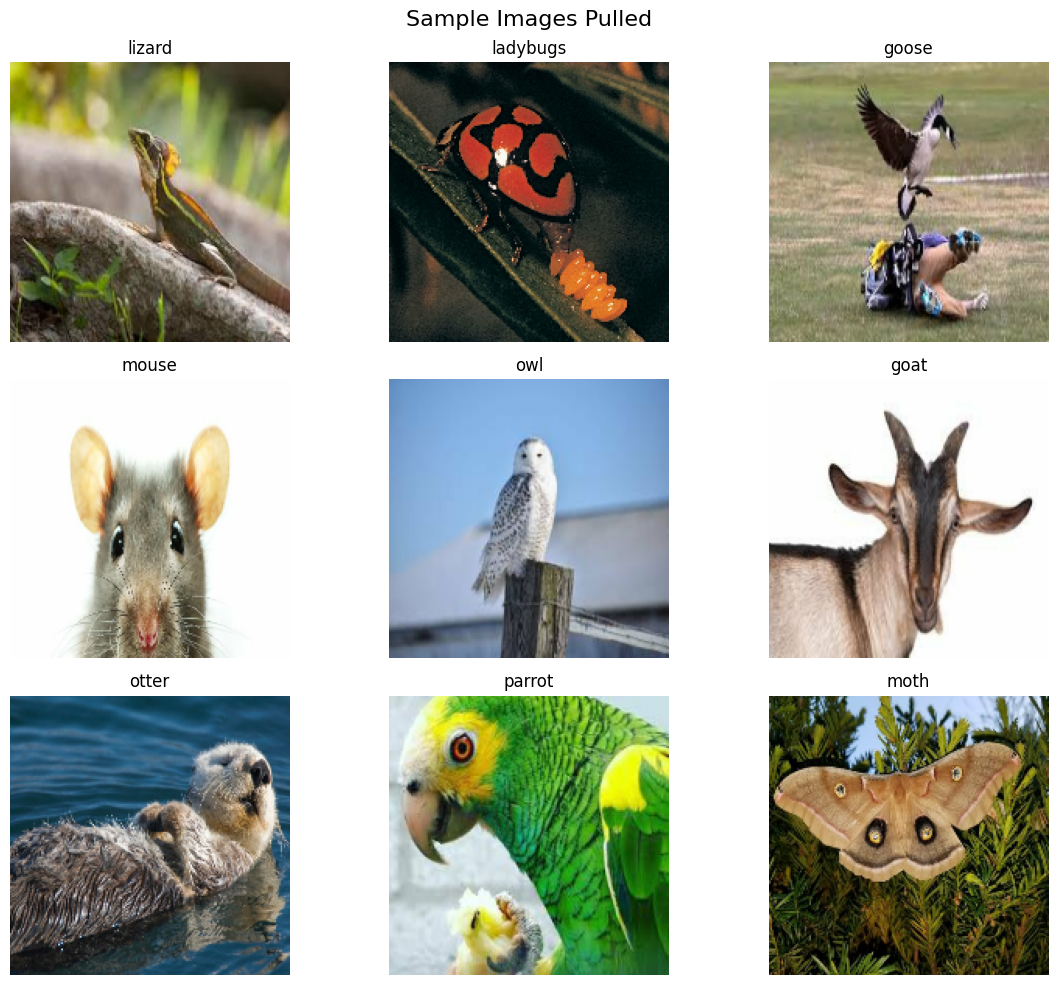

In [ ]:
#display animal images
#---------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

#one batch of training images
for images, labels in train_dataset.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        #display image
        plt.imshow(images[i].numpy().astype("uint8"))

        #display animal category
        animal_name = class_names[labels[i].numpy()]

        plt.title(animal_name)
        plt.axis("off")

plt.suptitle(
    "Sample Images Pulled",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:

#CNN model
#-----------

import tensorflow as tf
from tensorflow.keras import layers, models

#CNN architecture creation
model = models.Sequential([

    #normalize pixel values
    layers.Rescaling(1./255, input_shape=(180, 180, 3)),

    #1st convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #2nd convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #3rd convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #4th convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #conversion of feature maps into one-dimensional vector
    layers.Flatten(),

    #connected layer
    layers.Dense(256, activation='relu'),

    #overfitting help
    layers.Dropout(0.5),

    #output layer - 90 animal categories
    layers.Dense(len(class_names), activation='softmax')
])

#display CNN architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,654,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 90)             │        23,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,918,426 (11.13 MB)

 Trainable params: 2,918,426 (11.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#CNN model compilation
#---------------------

model.compile(

    #adjusts model weights during training
    optimizer='adam',

    #measures classification prediction errors
    loss='sparse_categorical_crossentropy',

    #prediction accuracy tracking
    metrics=['accuracy']
)

print("Compilation Completed")


Compilation Completed


In [ ]:

#CNN model training
#------------------

#model training
history = model.fit(

    train_dataset,

    #training iterations
    epochs=20, #1 epoch = processed training dataset once

    #after each epoch, test performance
    validation_data=test_dataset
)

print("Training Completed")


Epoch 1/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 54s 292ms/step - accuracy: 0.0095 - loss: 4.5018 - val_accuracy: 0.0000e+00 - val_loss: 4.4975
Epoch 2/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 151ms/step - accuracy: 0.0111 - loss: 4.5003 - val_accuracy: 0.0000e+00 - val_loss: 4.4978
Epoch 3/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 19s 137ms/step - accuracy: 0.0127 - loss: 4.4999 - val_accuracy: 0.0000e+00 - val_loss: 4.4987
Epoch 4/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 22s 146ms/step - accuracy: 0.0130 - loss: 4.4693 - val_accuracy: 0.0083 - val_loss: 4.1644
Epoch 5/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 19s 138ms/step - accuracy: 0.0208 - loss: 4.3990 - val_accuracy: 0.0231 - val_loss: 4.1424
Epoch 6/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 147ms/step - accuracy: 0.0275 - loss: 4.3551 - val_accuracy: 0.0731 - val_loss: 4.0643
Epoch 7/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 150ms/step - accuracy: 0.0410 - loss: 4.2579 - val_accuracy: 0.0306 - val_loss: 4.0987
Epoch 8/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 150ms/step - accuracy: 0.05

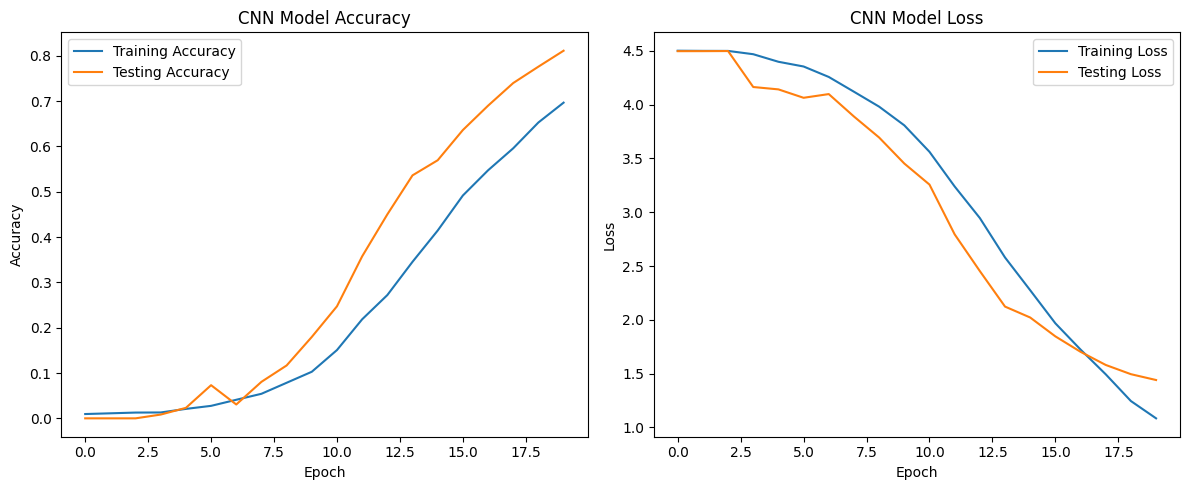

In [ ]:
#training accuracy and loss results graphs
#--------------------------------

import matplotlib.pyplot as plt

#plot training and testing accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Testing Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

#plot training and testing loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Testing Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
#CNN model performance
#--------------------

test_loss, test_accuracy = model.evaluate(test_dataset)

print("\nTesting Results")
print("---------------")

print(f"Testing Loss: {test_loss:.4f}")

print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")


34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.8111 - loss: 1.4411

Testing Results
---------------
Testing Loss: 1.4411
Testing Accuracy: 81.11%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


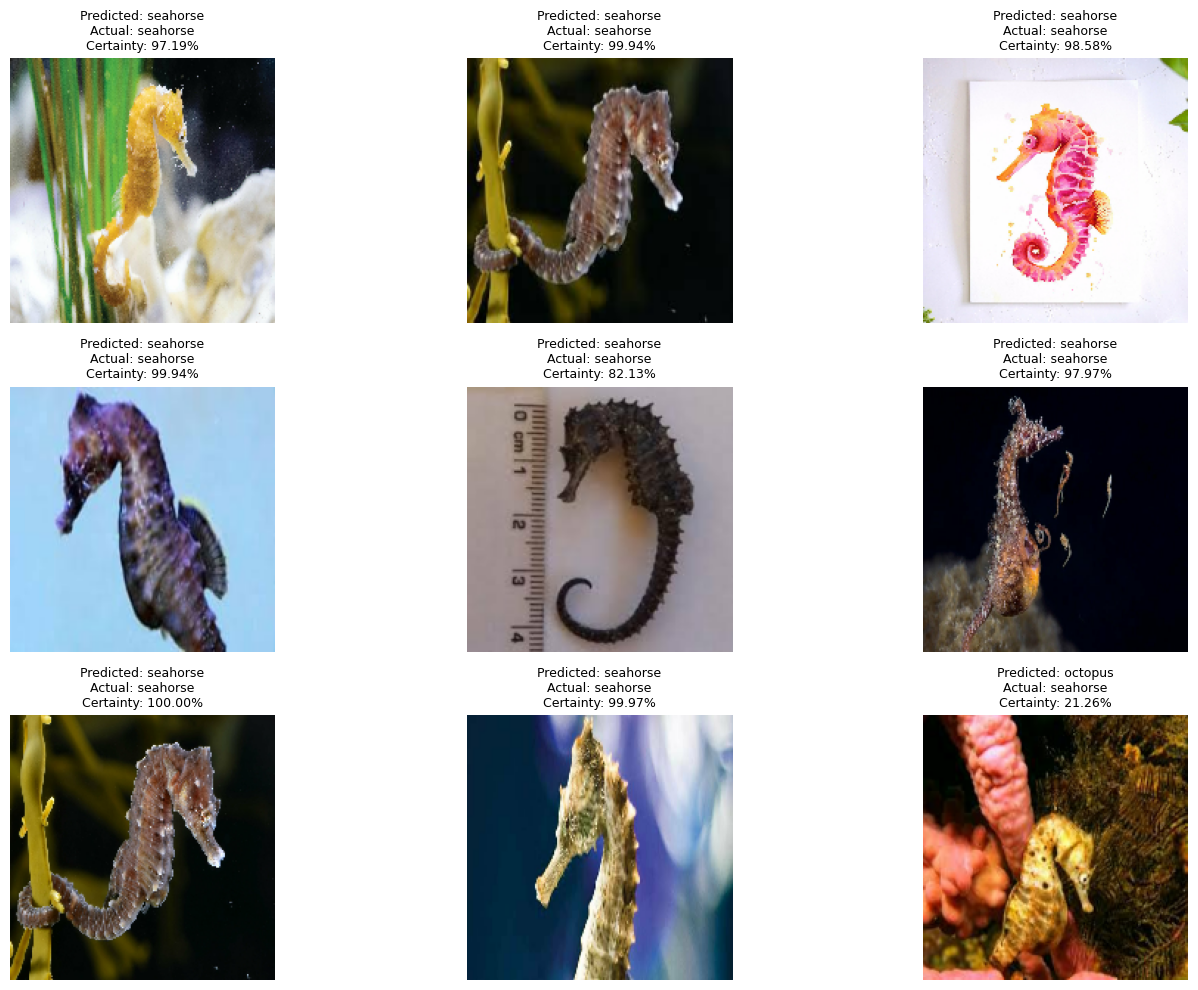

In [ ]:
#image predictions one by one
#----------------------------

import numpy as np
import matplotlib.pyplot as plt

#batch of test images
for images, labels in test_dataset.take(1):

    predictions = model.predict(images)

    plt.figure(figsize=(15, 10))

    for i in range(9):

        #predicted animal category
        predicted_index = np.argmax(predictions[i])

        predicted_animal = class_names[predicted_index]

        #actual animal category
        actual_animal = class_names[labels[i].numpy()]

        #prediction certainty
        certainty = predictions[i][predicted_index] * 100

        #display image and prediction
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            f"Predicted: {predicted_animal}\n"
            f"Actual: {actual_animal}\n"
            f"Certainty: {certainty:.2f}%",
            fontsize=9
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
#save training model
#-------------------

model.save("cnn_model_animal.keras")

print("Model Saved")

Model Saved
